# Sales Data Analysis Dashboard

This notebook documents data cleaning, exploratory analysis, forecasting, and business suggestions.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

from src.data_processing import ensure_processed_dataset
from src.eda import (
    plot_monthly_sales_trend,
    plot_category_sales,
    plot_sub_category_sales,
    plot_region_performance,
    plot_profit_vs_sales,
    plot_correlation_heatmap,
)
from src.forecasting import forecast_sales
from src.insights import compute_kpis, generate_business_suggestions

In [2]:
df = ensure_processed_dataset(force_rebuild=True)
print(f'Shape: {df.shape}')
df.head()

Shape: (1465, 14)


,Order ID,Order Date,Sales,Profit,Category,Sub-Category,Region,Customer Segment,Product Name,Unit Price,Quantity,Discount Percentage,Rating,Rating Count
0,ORD-00001,2023-01-02,3145.0,130.52,Computers&Accessories,Accessories&Peripherals,Central,Consumer,"Lenovo 400 Wireless Mouse, 1200DPI Optical Sen...",629.0,5,55,4.4,6301
1,ORD-00002,2023-01-02,1716.0,21.45,Home&Kitchen,Kitchen&HomeAppliances,West,Home Office,"Nirdambhay Mini Bag Sealer, 2 in 1 Heat Sealer...",429.0,4,57,3.0,617
2,ORD-00003,2023-01-02,9995.0,39.98,Electronics,WearableTechnology,West,Home Office,"Noise Pulse Buzz 1.69"" Bluetooth Calling Smart...",1999.0,5,60,3.9,7571
3,ORD-00004,2023-01-04,537.0,23.63,Computers&Accessories,Accessories&Peripherals,West,Home Office,MI 2-in-1 USB Type C Cable (Micro USB to Type ...,179.0,3,40,3.9,81
4,ORD-00005,2023-01-05,1116.0,66.96,Home&Kitchen,Kitchen&HomeAppliances,North,Home Office,INKULTURE Stainless_Steel Measuring Cups & Spo...,279.0,4,60,4.3,2326


In [3]:
print('Missing values by column:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('Date range:', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())

Missing values by column:
Order ID               0
Order Date             0
Sales                  0
Profit                 0
Category               0
Sub-Category           0
Region                 0
Customer Segment       0
Product Name           0
Unit Price             0
Quantity               0
Discount Percentage    0
Rating                 1
Rating Count           0
dtype: int64

Duplicate rows: 0
Date range: 2023-01-02 to 2025-12-31


In [4]:
kpis = compute_kpis(df)
kpis

{'total_sales': 22068210.67,
 'total_profit': 1351598.42,
 'total_orders': 1465,
 'avg_order_value': 15063.625030716725,
 'profit_margin': 6.12463982790137,
 'profit_known': True}

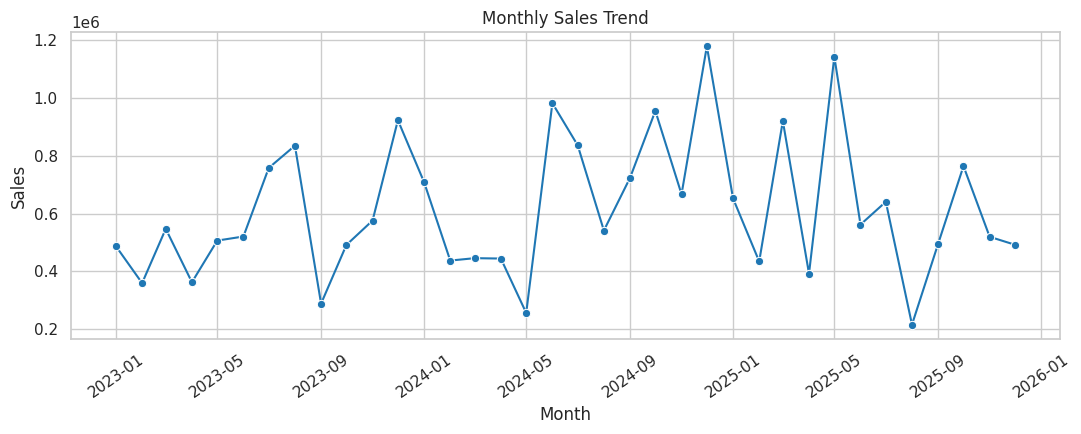

In [5]:
fig = plot_monthly_sales_trend(df)
display(fig)

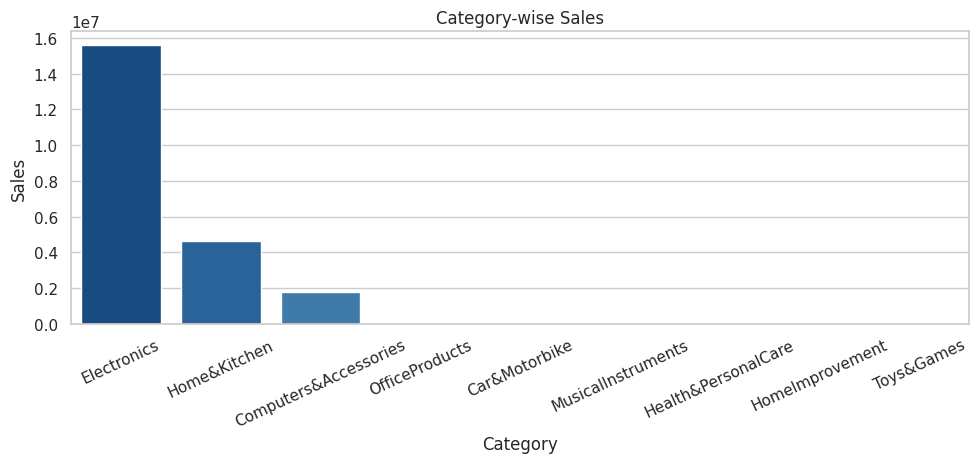

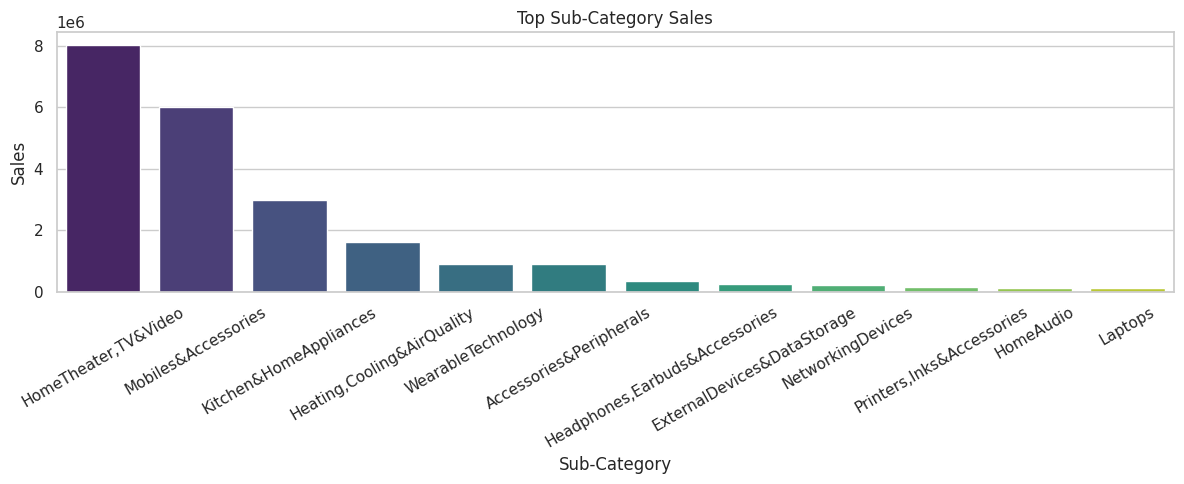

In [6]:
fig = plot_category_sales(df)
display(fig)

fig = plot_sub_category_sales(df)
display(fig)

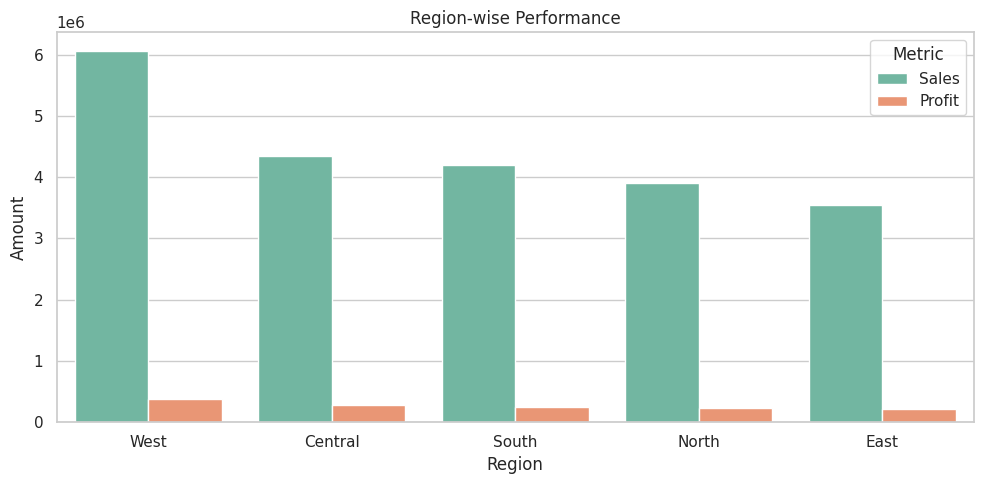

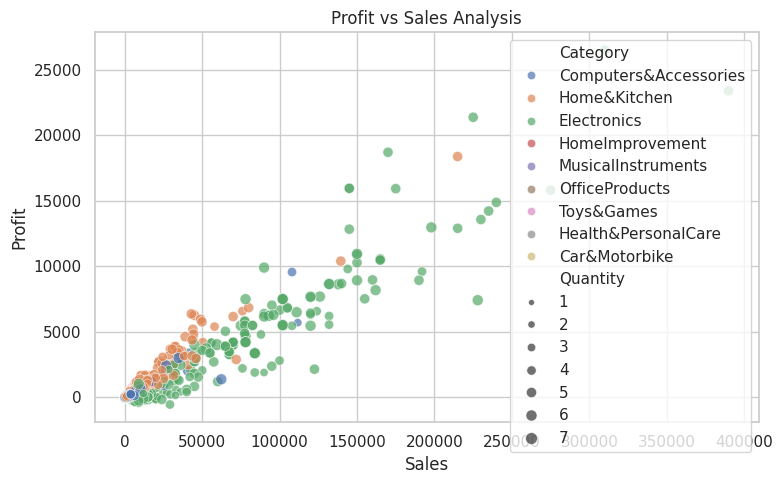

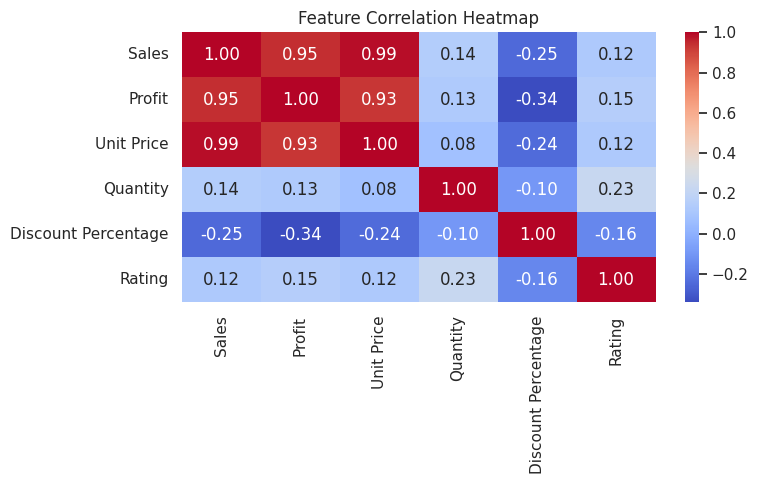

In [7]:
fig = plot_region_performance(df)
display(fig)

fig = plot_profit_vs_sales(df)
display(fig)

fig = plot_correlation_heatmap(df)
display(fig)

In [8]:
forecast_result = forecast_sales(df, periods=6)
forecast_result['forecast']

,Month,Predicted Sales,Lower Bound (80%),Upper Bound (80%)
0,2026-01-01,613409.633992,306183.019877,9.206362e+05
1,2026-02-01,613409.633992,178925.589589,1.047894e+06
2,2026-03-01,613409.633992,81277.528908,1.145542e+06
3,2026-04-01,613409.633992,0.000000,1.227863e+06
4,2026-05-01,613409.633992,0.000000,1.300389e+06
5,2026-06-01,613409.633992,0.000000,1.365958e+06


In [9]:
suggestions = generate_business_suggestions(df, forecast_result['forecast'])
for i, suggestion in enumerate(suggestions, start=1):
    print(f'{i}. {suggestion}')

1. Protect stock for 'Sony Bravia 164 cm (65 inches) 4K Ultra HD Smart LED Google TV KD-65X74K (Black)': ₹389,950 sales (1.8% of total) at 6.0% margin. Top 5 products together are 6.6% of sales.
2. 'Fire-Boltt Ninja Call Pro Plus 1.83" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sports Modes IP67 Rating, 240*280 Pixel High Resolution' lost ₹1,372 across 5 orders — review its price or discount, or delist it.
3. Orders with 20%+ discount made ₹18,821,140 sales but only 5.5% margin (average discount is 47.7%). Cap deep discounts on low-margin items.
4. Latest month (2025-12) sales were ₹492,419, down 5.3% vs the previous month (average month: ₹613,006).
5. 'Electronics' is the biggest category at ₹15,585,279 (70.6% of sales) — keep its best-selling SKUs in stock first.
6. Weakest region is 'East' with 6.1% margin — check discounting and delivery cost there before spending more on promotion.
7. Forecast is upward over the next 6 months: next month ₹613,410 (80% range ₹306,